In [2]:
from skimage import color, io, filters, morphology, measure, exposure, transform
import matplotlib.pyplot as plt
import numpy as np
import math
import scipy as sci
from scipy.optimize import fsolve
import pandas as pd
import seaborn as sns
from os import listdir
import os
import re

In [69]:
# DO NOT RERUN THIS CELL FOR THE SAME TRIAL: o/w will error unless you delete "Processed" folder

## Select which Trial to Run
run = str('20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)') #CHANGE ACCORDING TO TRIAL

## Make Directory to Save Data depending on User
direcFolder = str('./Runs/')
directory = direcFolder + run #if folder doesn't exist, makes the folder inside the folder this code file is currently in
os.makedirs(direcFolder + run + '/Processed_Data' )

## Make Files to Save Data
# Curve Equations to .txt
curve_eqns_filepath = direcFolder + run + '/Processed_Data/curve_equations.txt'
curve_eqns = open(curve_eqns_filepath, 'w')                                   #SAVE INFO TO A TXT FILE
curve_eqns.write('Filename,Cycle,x_offset,y_offset,a,b,RMSE')
curve_eqns.close()

# CA Data to .csv
data_sum_filepath = direcFolder + run + '/Processed_Data/data.csv'
data_sum = open(data_sum_filepath, 'w')                                       #SAVE INFO TO A CSV FILE
data_sum.write('Filename,Cycle,Left CA,Right CA,Left Cut,Right Cut, NRMSE')
data_sum.close()

### Determines Droplet Curve Comparing Derivative & Height Difference of Curves + Manual Pre-Lens Curve Offset

In [70]:
def readImages(directory):
    fname_list = [f'/{fname}' for fname in listdir(directory) if '.jpg' in fname]
    
    droplet_pic = sorted([f for f in fname_list if "/Image_" in f],
        key=lambda x: tuple(map(int, re.findall(r'\d+', x)))) # a '\d' means digit, adding + means one or more digits, to sort 10s properly
    
    lens_pic = sorted([f for f in fname_list if "/preLens_" in f or "/pre_lens" in f],
        key=lambda x: tuple(map(int, re.findall(r'\d+', x)))) #creates tuples, i.e., cycle1_run2 --> (1,2)
    
    return droplet_pic, lens_pic

def selectImages(selection, droplet_pic, lens_pic, experiment):
    if experiment == "B&R":
        if selection[0] == "all":    
            droplet_pic = droplet_pic[0:]
            lens_pic = lens_pic[0:]
        else:
            #create null lists to store desired droplet and lens pics
            dropletPic = []
            lensPic = []
            selection_pairs = set() #creates empty set

            def parse_name(fname):
                capture = re.search(r'run(\d+)_(?:cycle|drop)(\d+)', fname) #captures the numbers after run and after cycle/drop
                return tuple(map(int, capture.groups())) if capture else None
            
            # Collects the different run numbers from all droplet images
            all_run_nums = {parse_name(f)[0] for f in droplet_pic}
            
            if len(all_run_nums) == 1: #if only one run (for Blink)
                onlyRun_num = next(iter(all_run_nums)) #run value of the singular run
                for cycle in selection:
                    selection_pairs.add((onlyRun_num, cycle))
            else: #if more than 1 run (for Rewett)
                for s in selection:
                    selection_pairs.add(parse_name(s))

            dropletPic = [f for f in droplet_pic if parse_name(f) in selection_pairs]
            lensPic = [f for f in lens_pic if parse_name(f) in selection_pairs]
            
            droplet_pic = sorted(dropletPic, key=parse_name)
            lens_pic = sorted(lensPic, key=parse_name)
            
    elif experiment == "T&RH":
        if selection[0] == "all":    
            droplet_pic = droplet_pic[0:]
            lens_pic = lens_pic[0:]
        else:
            #create null lists to store desired droplet and lens pics
            dropletPic = []
            lensPic = []

            for j in selection:
                dropletPic = dropletPic + droplet_pic[j:j+1]
                lensPic = lensPic + lens_pic[j:j+1]

            droplet_pic = sorted(dropletPic)
            lens_pic = sorted(lensPic)
            
    print(droplet_pic)
    print(lens_pic)
    return droplet_pic, lens_pic

def test_droplet_img(directory, droplet_pic, img_crop_values):
    droplet_img = droplet_pic[0]
    img = io.imread(directory + droplet_img, as_gray=True)
    y1 = img_crop_values[0]
    y2 = img_crop_values[1]
    x1 = img_crop_values[2]
    x2 = img_crop_values[3]
    img_crop = img[y1:y2,x1:x2] #img_crop = img[300:1200,205:1405]
    
    print('Test Crop:', droplet_img.lstrip('/'))
    fig, ax = plt.subplots()   #CREATE PLOT
    ax.imshow(img_crop, cmap='Greys_r')

    return y1,y2,x1,x2


### FUNCTIONS FOR CA CACLULATIONS

# Equations
def ellipse_equation(x, x_offset, y_offset, a, b):
    val = (1 - (((x-x_offset)**2)/(a**2))) * (b**2)
    val = np.clip(val, 0, None)
    return np.sqrt(val) + y_offset

def ellipse_F(x, y, x0, y0, a, b):
    return ((x - x0)**2)/a**2 + ((y - y0)**2)/b**2 - 1

def ellipse_grad(x, y, x0, y0, a, b):
    Fx = 2*(x - x0)/a**2
    Fy = 2*(y - y0)/b**2
    return np.array([Fx, Fy])

def ellipse_distance(x, y, params):
    x0, y0, a, b = params

    F = ellipse_F(x, y, x0, y0, a, b)

    grad = ellipse_grad(x, y, x0, y0, a, b)
    grad_norm = np.linalg.norm(grad, axis=0)

    return np.abs(F) / grad_norm


def ellipse_tangent_dir(x, y, x0, y0, a, b):
    Fx, Fy = ellipse_grad(x, y, x0, y0, a, b)
    t = np.array([-Fy, Fx])   # perpendicular
    return t / np.linalg.norm(t)

def intersection_eq(p, e1, e2):
    x, y = p
    return [
        ellipse_F(x, y, *e1),
        ellipse_F(x, y, *e2)
    ]

def intersection_angle(x, y, e1, e2):
    g1 = ellipse_grad(x, y, *e1)
    g2 = ellipse_grad(x, y, *e2)

    cos_theta = np.dot(g1, g2) / (
        np.linalg.norm(g1) * np.linalg.norm(g2)
    )

    theta = np.arccos(np.clip(cos_theta, -1, 1))
    
    return theta

def line_equation(x, m, b):
    return (m * x) + b

# Processing Image & Droplet
def processed_image(directory, fname, y1,y2,x1,x2):
    img = io.imread(directory + fname, as_gray=False)                       #load image (in colour), img is NumPy array
    
    img_crop = img[y1:y2,x1:x2]                                             #CROP IMAGE: [y axis range, x axis range], may need to tune

    img_gray = color.rgb2gray(img_crop)                                     #GREYSCALE IMAGE

    img_blur = filters.gaussian(img_gray, sigma=5, preserve_range=True)     #BLUR IMAGE

    img_gamma_correct = exposure.adjust_gamma(img_blur, gamma=5)            #INCREASE CONTRAST

    thr = filters.threshold_otsu(img_gamma_correct)                         #PROVIDES THRESHOLD THAT DETERMINES WHICH PIXELS ARE IN FOREGROUND
    img_thr = img_gamma_correct > thr

    contours = measure.find_contours(img_thr)
    idx_max = np.argmax([len(contour) for contour in contours])             #FIND THE LONGEST CONTOUR
    main_contour = contours[idx_max]
    main_contour_x = np.flip(main_contour[:,1])
    main_contour_y = np.flip(img_crop.shape[0] - main_contour[:,0])

    return img, img_crop, img_thr, main_contour, main_contour_x, main_contour_y

def lensCurve(img_thr, ellipse_equation, main_contour_x, main_contour_y):
    #Determine Lens Curve Parameters
    p0 = (img_thr.shape[1]//2, 0, img_thr.shape[1]/2, img_thr.shape[0]/4)   #initial guess
    bounds = ([0, -img_thr.shape[0], 3, 1], [img_thr.shape[1], img_thr.shape[0], img_thr.shape[1], img_thr.shape[0]*7/4])
    
    params, _ = sci.optimize.curve_fit(ellipse_equation, main_contour_x, main_contour_y, p0=p0, bounds=bounds)
    print(f'Parameters of lens curve equation - x_offset, y_offset, a, b: {params}')

    # Determine Lens Curve
    lens_curve_x = main_contour_x
    lens_curve_y = ellipse_equation(main_contour_x, *params)

    # Determine Root Mean Square Error (RMSE) of Lens Curve
    sum_squared = 0
    for point in range(len(lens_curve_x)):
        sum_squared += (lens_curve_y[point] - main_contour_y[point])**2
    RMSE = math.sqrt(sum_squared/len(lens_curve_x))
    RMSE = round(RMSE,2)    

    return lens_curve_x, lens_curve_y, params, RMSE
    
# Determining Contours
def dropletContour(main_contour_x, main_contour_y, lens_curve_x, lens_curve_y, min_len): #min_len can be tuned
    mask_droplet = np.zeros(len(main_contour_x), dtype = bool) #initializes array for droplet contour
    
    for j in range(len(main_contour_x) - 40):                           #SEPARATE OUT THE DROPLET CONTOUR
        main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
        lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
        curve_diff = main_contour_y[j+10] - lens_curve_y[j+10] 

        if curve_diff > 5 and ((abs(main_contour_slope) > abs(1.5*lens_curve_slope)) or (abs(main_contour_slope) == math.inf)):     #if the main contour deviates enough from the lens curve
            mask_droplet[j+10] = True

    indices = np.where(mask_droplet)[0]
    splits = np.where(np.diff(indices) > 30)[0] #np.diff() calculates the discerete differences along "indices": output[i] = indices[i+1] - indices[i]
    segments = np.split(indices, splits + 1) #np.split(array, sections): splits array along the entries in sections

    segments = [seg for seg in segments if len(seg) >= min_len]

    largest_segment = np.concatenate(segments)

    droplet_contour_x = main_contour_x[largest_segment]
    droplet_contour_y = main_contour_y[largest_segment]

    droplet_contour_x = np.asarray(droplet_contour_x)
    droplet_contour_y = np.asarray(droplet_contour_y)

    return droplet_contour_x, droplet_contour_y

def ellipseInitialGuess(droplet_contour_x, droplet_contour_y):
    p0_1 = (droplet_contour_x[0] + droplet_contour_x[-1])/ 2
    p0_3 = (max(droplet_contour_x)-droplet_contour_x[0])/2
    p0_4 = (max(droplet_contour_y)-droplet_contour_y[0])/4
    
    p0_drop = (p0_1, droplet_contour_y[0], p0_3, p0_4) #SET THE INITIAL GUESS FOR THE PARAMETERS FOR DROPLET CURVE
    
    return p0_drop

def ellipseIntersections(droplet_contour_x, droplet_contour_y, p0_drop, img, params):
    params_drop, _ = sci.optimize.curve_fit(ellipse_equation, droplet_contour_x, droplet_contour_y, p0=p0_drop, bounds = ([0, -img.shape[0], 0.5, 0.5], [img.shape[1], img.shape[0], img.shape[1], img.shape[0]*7/4]))
    print('Parameters of droplet curve equation - x_offset, y_offset, a, b:', params_drop)
    
    x_0, y_0, a, b = params_drop

    droplet_curve_x_top = np.linspace(x_0 - a, x_0 + a, 1000)           #CREATE ELLIPSE AROUND DROPLET
    droplet_curve_x_bottom = np.linspace(x_0 + a, x_0 - a, 1000)
    
    droplet_curve_y_top = ellipse_equation(droplet_curve_x_top, *params_drop)
    droplet_curve_y_bottom = 2*params_drop[1] - droplet_curve_y_top

    droplet_curve_x = np.concatenate((droplet_curve_x_top, droplet_curve_x_bottom))
    droplet_curve_y = np.concatenate((droplet_curve_y_top, droplet_curve_y_bottom))

                                                                         #DETERMINE INTERSECTION POINTS BTWN ELLIPSES 
    guesses = [(x_0 - a, y_0),   # left
               (x_0 + a, y_0)]   # right
    solutions = []
    
    for p0 in guesses:                                                 #FIND INTERSECTIONS AND ANGLE BETWEEN CURVES
        x_int, y_int = fsolve(intersection_eq, p0, args=(params, params_drop))
        solutions.append((x_int, y_int))

    return params_drop, droplet_curve_x, droplet_curve_y, solutions

def findNRMSE(params_drop, solutions, droplet_contour_x, droplet_contour_y, droplet_curve_x):
    y_int_lower = np.min([solutions[0][1], solutions[1][1]])
    y_int_greater = np.max([solutions[0][1], solutions[1][1]])
    
    y_cut = y_int_greater + (0.25 * (np.max(droplet_contour_y) - y_int_greater))
    mask = droplet_contour_y <= y_cut
    
    x_test = droplet_contour_x[mask]
    y_test = droplet_contour_y[mask]
    
    d = ellipse_distance(x_test, y_test, params_drop)
    
    RMSE = np.sqrt(np.mean(d**2))
    
    footprint_radius = 0.5 * (droplet_curve_x.max() - droplet_curve_x.min())
    NRMSE = RMSE / footprint_radius

    return NRMSE

def ellipseCA(CA, solutions, params, params_drop):
    for x_int, y_int in solutions: 
        theta = intersection_angle(x_int, y_int, params, params_drop) 
        theta_deg = np.degrees(theta)
        CA.append(round(theta_deg, 2))

    return CA

def ellipseTangentPoints(solutions, params, params_drop):
    L1x_list, L1y_list, L2x_list, L2y_list = [], [], [], [] #MAKE EMPTY LISTS
    #
    for soln in range(len(solutions)):                                 #FIND TANGENT LINE POINTS
        x, y = solutions[soln]
        t1 = ellipse_tangent_dir(x, y, *params)
        t2 = ellipse_tangent_dir(x, y, *params_drop)

        s = np.linspace(-100, 100, 100)
        
        # Tangent line points
        L1x = x + s * t1[0]
        L1y = y + s * t1[1]
        
        L2x = x + s * t2[0]
        L2y = y + s * t2[1]

        L1x_list.append(L1x)
        L1y_list.append(L1y)
        L2x_list.append(L2x)
        L2y_list.append(L2y)

    return L1x_list, L1y_list, L2x_list, L2y_list

    
def cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y):
    #redefine contour values to cropped contour values
    if right_cut > 1 :
        droplet_contour_x = droplet_contour_x[left_cut:-right_cut] 
        droplet_contour_y = droplet_contour_y[left_cut:-right_cut]
    else:
        droplet_contour_x = droplet_contour_x[left_cut:] 
        droplet_contour_y = droplet_contour_y[left_cut:]
        
    return droplet_contour_x, droplet_contour_y
    
# Calculated CAs
def leftCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y): #used in cut_leftCA
    #Determine right contact angle
    left_drop_vector = [droplet_contour_x[10] - droplet_contour_x[0], droplet_contour_y[10] - droplet_contour_y[0]] #OBTAIN DROPLET VECTOR
    left_drop_slope = left_drop_vector[1]/left_drop_vector[0]
    left_drop_intercept = droplet_contour_y[0] - (left_drop_slope * droplet_contour_x[0])

    left_index = np.argwhere(lens_curve_x == droplet_contour_x[0])[0]
    left_lens_vector = [lens_curve_x[left_index[0] + 5] - lens_curve_x[left_index[0]- 5], lens_curve_y[left_index[0] + 5] - lens_curve_y[left_index[0]- 5] ]
    left_lens_slope = left_lens_vector[1]/left_lens_vector[0]
    left_lens_intercept = lens_curve_y[left_index[0]] - (left_lens_slope * lens_curve_x[left_index[0]])

    #Calculate left CA
    left_CA = np.arccos(np.dot(left_lens_vector,left_drop_vector) / (np.linalg.norm(left_lens_vector) * np.linalg.norm(left_drop_vector))) * 180/math.pi
    left_CA = round(left_CA,2)

    return left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA

def rightCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y): #used in cut_rightCA
    right_drop_vector = [droplet_contour_x[-11] - droplet_contour_x[-1], droplet_contour_y[-11] - droplet_contour_y[-1]] #OBTAIN DROPLET VECTOR
    right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
    right_drop_intercept = droplet_contour_y[-1] - (right_drop_slope * droplet_contour_x[-1])

    right_index = np.argwhere(lens_curve_x == droplet_contour_x[-1])[0]
    right_lens_vector = [lens_curve_x[right_index[0] - 5] - lens_curve_x[right_index[0] + 5], lens_curve_y[right_index[0] -5] - lens_curve_y[right_index[0] + 5] ]
    right_lens_slope = right_lens_vector[1]/right_lens_vector[0]
    right_lens_intercept = lens_curve_y[right_index[0]] - (right_lens_slope * lens_curve_x[right_index[0]])

    #Calculate right CA
    right_CA = np.arccos(np.dot(right_lens_vector,right_drop_vector) / (np.linalg.norm(right_lens_vector) * np.linalg.norm(right_drop_vector))) * 180/math.pi
    right_CA = round(right_CA,2)

    return right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA

def cut_leftCA(autoLeft, left_cut, offset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    #Get initial value for the following variables
    left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
    counter = left_cut #b/c need to return this value
    
    if autoLeft == False: # Manual Cutting Droplet Contour (cuts both sides)
        if left_cut != 0:
            droplet_contour_xLEFT, droplet_contour_yLEFT = cutFunc(left_cut, 0, droplet_contour_x, droplet_contour_y) #set right_cut to 0 since not doing that side
            left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_xLEFT, droplet_contour_yLEFT, lens_curve_x, lens_curve_y)
    else: #Automatically Cut droplet_contour based on Left Tangent
        left_cut = 0
        right_cut = 0 #need this b/c cutFunc uses it
        toCut = False
        runCut = True 
        
        cut_index = np.argwhere(main_contour_x == droplet_contour_x[offset])[0] #starting index of where to cut
        
        while runCut:
            for k in range(len(droplet_contour_x)):
                if k == 0: #otherwise, use the save_droplet_contour_y from previous run
                    save_droplet_contour_y = droplet_contour_y[offset]
                    
                if left_drop_slope >= 0:
                    condition = save_droplet_contour_y > (line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept))
                elif left_drop_slope < 0: #or left_drop_slope == float('inf'):
                    condition = save_droplet_contour_y < (line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept))
                elif left_drop_slope == float('inf'):
                    conditions = droplet_contour_xLEFT[k + offset] < main_contour_x[cut_index]
                    
                if condition:
                    toCut = True
                    left_cut = 1 #cut an additional 1 point, not += 1 b/c droplet_contour is already cut from previous run

                    #Cut left side and recalculate left CA
                    droplet_contour_x, droplet_contour_y = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
                    left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
    
                    cut_index = np.argwhere(main_contour_x == droplet_contour_x[k + offset])[0] #recalculate where to cut
                    save_droplet_contour_y = droplet_contour_y[k + offset]
                    counter += 1
                    
                else:
                    if counter == 0 and toCut == False:
                        print(f'NO LEFT CUT NEEDED')
                    print("LEFT SIDE:")
                    print('droplet contour y: ', save_droplet_contour_y, 'vs tangent line y : ', line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept)[0] )
                    print('droplet contour x: ', droplet_contour_x[k + offset] , 'vs tangent line x : ', main_contour_x[cut_index], '\n')
                    runCut = False
                    break

            # #Failsafe: for when toCut stays False up until end of droplet_contour_yLEFT length
            # if counter == len(droplet_contour_yLEFT) and toCut == False: #to prevent infinite recursion
            #     runCut = False
    
    return droplet_contour_x, droplet_contour_y, left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA, counter #counter = how many points left side was cut (aka left_cut)

def cut_rightCA(autoRight, right_cut, offset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    #Get initial value for the following variables
    right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
    
    if autoRight == False: # Manual Cutting Droplet Contour (cuts both sides)
        if right_cut != 0:
            droplet_contour_xRIGHT, droplet_contour_yRIGHT = cutFunc(0, right_cut, droplet_contour_x, droplet_contour_y) #set left_cut to 0 since not doing that side
            right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_xRIGHT, droplet_contour_yRIGHT, lens_curve_x, lens_curve_y)
    else: #Automatically Cut droplet_contour based on Right Tangent
        left_cut = 0 #need this b/c cutFunc uses it
        right_cut = 1
        toCut = False
        runCut = True
        
        cut_index = np.argwhere(main_contour_x == droplet_contour_x[-offset])[0] #starting index of where to cut
        
        # # #Making new droplet and main contours to change for right side only
        droplet_contour_xRIGHT = droplet_contour_x
        droplet_contour_yRIGHT = droplet_contour_y
    
        counter = 0
        while runCut:
            for k in range(len(droplet_contour_x)):
                if k == 0: #otherwise, use the save_droplet_contour_y from previous run
                    save_droplet_contour_y = droplet_contour_y[-offset]
    
                if right_drop_slope < 0:
                    condition = save_droplet_contour_y > (line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept))
                elif right_drop_slope >= 0: #or right_drop_slope == float('inf'):
                   condition = save_droplet_contour_y < (line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept))
                elif right_drop_slope == float('inf'):
                    conditions = droplet_contour_x[- (k + offset)] > main_contour_x[cut_index]
                    
                if condition:
                    toCut = True
                    right_cut += 1 #cut an additional 1 point,
                    droplet_contour_xRIGHT, droplet_contour_yRIGHT = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
                    
                    right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_xRIGHT, droplet_contour_yRIGHT, lens_curve_x, lens_curve_y)
    
                    cut_index -= 1  #before: cut_index = np.argwhere(main_contour_x == droplet_contour_x[-(k + offset)])[0]
                    save_droplet_contour_y = droplet_contour_y[-(k + offset)]
                    counter += 1

                else:
                    if counter == 0 and toCut == False:
                        print(f'NO RIGHT CUT NEEDED')
                    print("RIGHT SIDE:")
                    print('droplet contour y: ', save_droplet_contour_y, 'vs tangent line y: ', line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept)[0] )
                    print('droplet contour x: ', droplet_contour_x[-(k + offset)] , 'vs tangent line x : ', main_contour_x[cut_index], '\n')
                    runCut = False
                    break

            # #Failsafe: for when toCut stays False up until end of droplet_contour_yRIGHT length
            # if counter == len(droplet_contour_yRIGHT) and toCut == False: #to prevent infinite recursion
            #     runCut = False
    
    return droplet_contour_x, droplet_contour_y, right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA, right_cut
    

In [71]:
def combined(droplet_pic, lens_pic, directory, y1,y2,x1,x2, min_len, autoLeft, autoRight, leftOffset, rightOffset, left_cut, right_cut, left, right, curve_eqns_filepath, data_sum_filepath):
    drop = False
    count = 1
    
    for i in range(len(droplet_pic)):
        ellipse_method = True
        for j in range(2):
            if count % 2 == 0 :
                fname = droplet_pic[i] # "Image_"
                drop = True
            else:
                fname = lens_pic[i] # "preLens_"
                drop = False
    
            print(count) # pic count
            count += 1
            print(fname) # pic name
    
            ### CROP IMAGE & FIND FOREGROUND CONTOURS
            img, img_crop, img_thr, main_contour, main_contour_x, main_contour_y = processed_image(directory, fname, y1,y2,x1,x2)
    
            ### PLOT IMAGES & BASE CONTOUR (blue)
            fig, ax = plt.subplots(figsize=(10, 6))                                 #CREATE PLOT
            ax.imshow(img_thr, cmap='Greys_r', extent=(0, img_crop.shape[1], 0, img_crop.shape[0]))
            ax.set_title(fname)
            ax.set_ylim([0, img_crop.shape[0]])
            ax.plot(main_contour_x, main_contour_y, label='Main Contour')                                 #PLOT THE MAIN CONTOUR (BASE CONTOUR)
    
            ### FIND "preLens_.img" LENS CONTOUR (red)
            if drop == False: #when it's "preLens_" image (not "if" b/c expected to reach this statement)
                ## Determine Lens Curve & RMSE
                lens_curve_x, lens_curve_y, params, RMSE = lensCurve(img_thr, ellipse_equation, main_contour_x, main_contour_y)
                x_0, y_0, a, b = params   #separating params = [p0, p1, p2, p3] into 4 variables for saving later
                RMSE_summary = 'RMSE: ' + str(RMSE)
                
                ax.plot(lens_curve_x, lens_curve_y, 'r', linewidth=2)               #PLOT LENS CURVE (red)      
                ax.text(20, 700, RMSE_summary, fontsize=12)                         #DISPLAY RMSE IN PLOT
                
                ## Save Info: params, RMSE
                curve_eqns = open(curve_eqns_filepath, 'w')                         #SAVE INFO TO A TXT FILE
                curve_eqns.write('\n' + fname + ',' + str(i) +','+ str(x_0) + ',' + str(y_0) + ',' + str(a) + ',' + str(b) + ',' + str(RMSE))
                curve_eqns.close()
    
            if drop == True: #when it's "Image_" (expected to occur after drop == False runs)
                #Using params found in drop == False, set up lens curve again so that it will be the same length as main contour
                lens_curve_x = main_contour_x
                lens_curve_y = ellipse_equation(main_contour_x, *params)
                
                ## Determine Droplet Contour
                droplet_contour_x, droplet_contour_y = dropletContour(main_contour_x, main_contour_y, lens_curve_x, lens_curve_y, min_len)
    
                ax.plot(droplet_contour_x, droplet_contour_y)                       #PLOT SEPARATED DROPLET CONTOUR (orange)
                
                '''ELLIPSE METHOD'''
                if ellipse_method == True:
                    print(f'RUNNING ELLIPSE METHOD:')
                    p0_drop = ellipseInitialGuess(droplet_contour_x, droplet_contour_y)  #SET THE INITIAL GUESS FOR THE PARAMETERS FOR DROPLET CURVE

                    try:
                        params_drop, droplet_curve_x, droplet_curve_y, solutions = ellipseIntersections(droplet_contour_x, droplet_contour_y, p0_drop, img, params) #FIND INTERSECTIONS BETWEEN ELLIPSE CURVES
    
                        NRMSE = findNRMSE(params_drop, solutions, droplet_contour_x, droplet_contour_y, droplet_curve_x) #DETERMINE NRMSE USING AREA CLOSE TO POINT OF INTERSECTION
                        print('NRSME: ' + str(NRMSE))
                        
                        CA = []        #MAKE EMPTY LIST FOR SAVING CA
                    
                    except:
                        NRMSE = 1000

                    if NRMSE < 0.005:
                        ax.plot(lens_curve_x, lens_curve_y, 'r', linewidth=2, label='Lens Curve')               #PLOT LENS CURVE
                        ax.plot(droplet_contour_x, droplet_contour_y, label='Interface Tangents')               #PLOT DROPLET CONTOUR INTERFACING TANGENTS
                        ax.plot(droplet_curve_x, droplet_curve_y, 'g', linewidth = 2, label='Droplet Curve')    #PLOT DROPLET CURVE

                        CA = ellipseCA(CA, solutions, params, params_drop)

                        L1x_list, L1y_list, L2x_list, L2y_list = ellipseTangentPoints(solutions, params, params_drop)

                        for s in range(len(solutions)):                                                          #PLOT TANGENT LINES FOR VISUALIZATION
                            ax.plot(L1x_list[s], L1y_list[s], 'orange', linewidth = 2)
                            ax.plot(L2x_list[s], L2y_list[s], 'orange', linewidth = 2)

                        summary = 'Left CA is: ' + str(CA[0]) + ' ° \nRight CA is: ' + str(CA[1]) + ' °'        
                        ax.text(10, 800, summary, fontsize=12)
                        #ax.legend(facecolor='white', framealpha=1, loc = 'lower left', bbox_to_anchor=(0, 0.17), prop={'family': 'Arial', 'size': 8.5})
                    
                        data_sum = open(data_sum_filepath, 'a')                                       #SAVE INFO TO A TXT FILE
                        data_sum.write('\n' + fname + ',' + str(i) + ',' + str(CA[0]) + ',' + str(CA[1])+ ',N/A,N/A,' + str(NRMSE))
                        data_sum.close()
                    else:
                        ellipse_method = False


                '''TANGENT METHOD:'''
                if ellipse_method == False:
                    print(f'\nRUNNING TANGENT METHOD:')
                    #save current contour values to diff variable, need when plotting ax2
                    old_droplet_contour_x = droplet_contour_x
                    old_droplet_contour_y = droplet_contour_y
                    
                    ## Determine Left Contact Angle (CA)
                    if left:
                        droplet_contour_xLEFT, droplet_contour_yLEFT, left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA, left_cut = cut_leftCA(autoLeft, left_cut, leftOffset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
                    else:
                        left_CA = None
                        
                    ## Determine Right Contact Angle (CA)
                    if right:
                        droplet_contour_xRIGHT, droplet_contour_yRIGHT, right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA, right_cut = cut_rightCA(autoRight, right_cut, rightOffset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
                    else:
                        right_CA = None
    
                    # Getting cropped droplet_contour with left and right crops showing
                    droplet_contour_x_cropped, droplet_contour_y_cropped = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
    
                    ax.plot(droplet_contour_x_cropped, droplet_contour_y_cropped)       #PLOT CROPPED DROPLET CONTOUR (green)     
                    ax.plot(lens_curve_x, lens_curve_y)                                 #PLOT LENS CURVE (red)
                    
                    ## Make New plot for Visualizing CA Tangent Lines
                    fig2, ax2 = plt.subplots(figsize=(10, 6))                            #CREATE NEW PLOT
                    ax2.imshow(img_thr, cmap='Greys_r', extent=(0, img_crop.shape[1], 0, img_crop.shape[0]))
                    ax2.set_title(fname)
                    ax2.set_ylim([0, img_crop.shape[0]])
                    
                    #Plotting old curves on the New Plot (must be in this same order to be the same colours)
                    ax2.plot(main_contour_x, main_contour_y)
                    ax2.plot(old_droplet_contour_x, old_droplet_contour_y)
                    ax2.plot(droplet_contour_x_cropped, droplet_contour_y_cropped)
                    ax2.plot(lens_curve_x, lens_curve_y)
        
                    #Plotting Left CA Tangent Lines                                       #VISUALIZE TANGENT LINES
                    if left:
                        ax2.plot(main_contour_x, line_equation(main_contour_x, left_drop_slope, left_drop_intercept), linewidth = 1)    
                        if left_drop_slope == float('inf'):
                            if autoLeft == True:
                                ax2.axvline(droplet_contour_x_cropped[0], linewidth=1) #droplet_contour_xLEFT[0] --> droplet_contour_xLEFT[left_cut]
                            else:
                                ax2.axvline(droplet_contour_x[left_cut], linewidth=1) #droplet_contour_x[0] --> droplet_contour_x[left_cut]
                        ax2.plot(main_contour_x, line_equation(main_contour_x, left_lens_slope, left_lens_intercept), linewidth = 1)
                    
                    #Plotting Right CA Tangent Lines                                       #VISUALIZE TANGENT LINES
                    if right:
                        ax2.plot(main_contour_x, line_equation(main_contour_x, right_drop_slope, right_drop_intercept), linewidth = 1)
                        if right_drop_slope == float('inf'):
                            if autoRight == True:
                                ax2.axvline(droplet_contour_x_cropped[-1], linewidth=1) #droplet_contour_xRIGHT[-1] --> droplet_contour_xRIGHT[-(right_cut-1)]
                            else:
                                ax2.axvline(droplet_contour_x[-right_cut], linewidth=1) #droplet_contour_x[-1]
                        ax2.plot(main_contour_x, line_equation(main_contour_x, right_lens_slope, right_lens_intercept), linewidth = 1)
                        
                    ## Save Data to Excel File
                    data_sum = open(data_sum_filepath, 'a')                                #SAVE INFO TO A CSV FILE
                    data_sum.write('\n' + fname + ',' + str(i) + ',' + str(left_CA) + ',' + str(right_CA) + ',' + str(left_cut) + ',' + str(right_cut-1) + ',' + str(NRMSE))
                    data_sum.close()
            
                    summary = 'Left CA is: ' + str(left_CA) + ' ° \nRight CA is: ' + str(right_CA) + ' °'        
                    ax2.text(10, 800, summary, fontsize=12)
    
                    print(f'left_cut = {left_cut}')
                    print(f'right_cut = {right_cut-1}')
            
        plt.show()
        #fig.savefig(direcFolder + run + '/Processed_Data/'+ str(i)+'.png') #SAVE PLOTS (WITHOUT TANGENTS) AS IMAGES
        #fig2.savefig(direcFolder + run + '/Processed_Data/'+ str(i)+'.png') #SAVE PLOTS (WITH TANGENTS) AS IMAGES
        
        base_path = f'./Runs/{run}/Processed_Data/'
        os.makedirs(base_path, exist_ok=True)
        
        filename = f"{droplet_pic[i].replace('.jpg', '').replace('/Image_', '')}_#0.png"
        full_path = os.path.join(base_path, filename)
        print(f'filename: {filename}')
        print(f'full_path: {full_path}')
        
        # If file exists, increment suffix
        counter = 1
        while os.path.exists(full_path):
            filename = f"{droplet_pic[i].replace('.jpg', '').replace('/Image_', '')}_#{counter}.png"
            full_path = os.path.join(base_path, filename)
            counter += 1

        if ellipse_method == True:
            fig.savefig(full_path)
        else:
            fig2.savefig(full_path)

    ## Write "End of Run" in CSV File
    data_sum = open(data_sum_filepath, 'a')
    if ellipse_method == True:
         data_sum.write(f'\n End of Run, ellipse method') #to help separate betweem multiple runs
    else:
        if autoLeft == False and autoRight == False:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_cut={left_cut} | right_cut={right_cut-1}') #to help separate betweem multiple runs
        elif autoLeft == True and autoRight == False:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, leftOffset={leftOffset} | right_cut={right_cut-1}') #to help separate betweem multiple runs
        elif autoLeft == False and autoRight == True:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_cut={left_cut} | rightOffset={rightOffset}') #to help separate betweem multiple runs
        else: #if autoLeft and autoRight both True
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, leftOffset={leftOffset} | rightOffset={rightOffset}') #to help separate betweem multiple runs
    data_sum.close()

['/Image_0.jpg', '/Image_1.jpg', '/Image_2.jpg', '/Image_3.jpg', '/Image_4.jpg', '/Image_5.jpg', '/Image_6.jpg', '/Image_7.jpg', '/Image_8.jpg', '/Image_9.jpg']
['/pre_lens_0.jpg', '/pre_lens_1.jpg', '/pre_lens_2.jpg', '/pre_lens_3.jpg', '/pre_lens_4.jpg', '/pre_lens_5.jpg', '/pre_lens_6.jpg', '/pre_lens_7.jpg', '/pre_lens_8.jpg', '/pre_lens_9.jpg']

Test Crop: Image_0.jpg


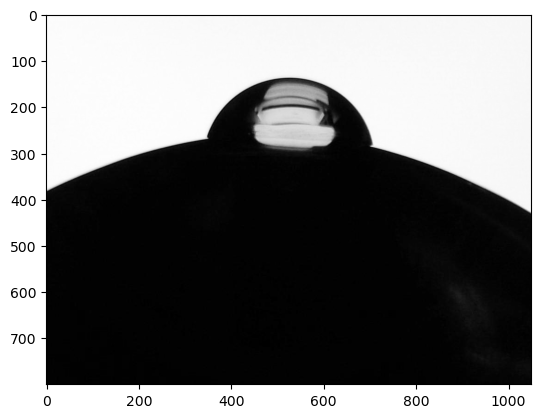

In [72]:
def test_image_size(): # MUST MANUALLY CHANGE (won't update from changes in def main())
    ### CELL TO TEST droplet image crop without running whole code
    ## Pick which Images
    selection = ["all"]  #CHANGE based run, i.e. B&R: [1,2,3,...], ["run1_cycle1","run2_cycle1"] or ["all"]; T&RH: [0,1,2,3...] OR [all]
    
    droplet_pic, lens_pic = readImages(directory)
    experiment = "T&RH" #either "T&RH" or "B&R"
    droplet_pic, lens_pic = selectImages(selection, droplet_pic, lens_pic, experiment)
    print() #to make a new line
    
    ## Adjust Image Crop
    img_crop_values = [400, 1200, 300, 1350]   #CHANGE based on droplet image; img_crop_values: [y1, y2, x1, x2] --> img_crop = img[y1:y2,x1:x2]
    
    y1,y2,x1,x2 = test_droplet_img(directory, droplet_pic, img_crop_values)
test_image_size()

In [73]:
#Edit info here, run it after running all other functions
def main(directory, curve_eqns_filepath, data_sum_filepath):
    ## Pick which Images
    selection = ["all"]  #CHANGE based run, i.e. B&R: [1,2,3,...], ["run1_drop1","run2_drop1"] or ["all"]; T&RH: [0,1,2,3...] OR [all]
    
    droplet_pic, lens_pic = readImages(directory)
    experiment = "T&RH" #either "T&RH" or "B&R"

    droplet_pic, lens_pic = selectImages(selection, droplet_pic, lens_pic, experiment)

    print() #to make a new line
    
    # Adjust Image Crop
    img_crop_values = [300, 1300, 300, 1300]   #CHANGE based on droplet image; img_crop_values: [y1, y2, x1, x2] --> img_crop = img[y1:y2,x1:x2]
    
    y1,y2,x1,x2 = test_droplet_img(directory, droplet_pic, img_crop_values)
    print() #to make a new line

    # curve_eqns_filepath, data_sum_filepath = createDataSave_FilePath()
    
    ## Adjust Contours
    min_len = 80        #CHANGE: min length of droplet that code looks for
    
    autoLeft = True    #CHANGE: automatically cut leftCA if needed? if False, left_cut cannot be 0
    autoRight = True   #CHANGE: automatically cut rightCA if needed? if False, right_cut cannot be 0
    leftOffset = 30    #CHANGE: num of offset points from tangent point when automatically cutting left CA: 30 for highCA, 50 for lowCA
    rightOffset = 30   #CHANGE: num of offset points from tangent point when automatically cutting right CA: 31 for highCA, 51 for lowCA
    rightOffset += 1   #DO NOT CHANGE: +1 to account for index [-1] being last digit, where index [-2] is a cut of 1
    
    left_cut = 0       #CHANGE: how much it cuts from left side of droplet (only works if autoLeft = False)
    right_cut = 0    #CHANGE: how much it cuts from right side of droplet (only works if autoRight = False)
    right_cut += 1     #DO NOT CHANGE: +1 to account for index [-1] being last digit, where index [-2] is a cut of 1
    left = True        #CHANGE: calculate left CA?
    right = True       #CHANGE: calculate right CA?
    
    runCode = True
    
    if runCode == True:
        combined(droplet_pic, lens_pic, directory, y1,y2,x1,x2, min_len, autoLeft, autoRight, leftOffset, rightOffset, left_cut, right_cut, left, right, curve_eqns_filepath, data_sum_filepath)

['/Image_0.jpg', '/Image_1.jpg', '/Image_2.jpg', '/Image_3.jpg', '/Image_4.jpg', '/Image_5.jpg', '/Image_6.jpg', '/Image_7.jpg', '/Image_8.jpg', '/Image_9.jpg']
['/pre_lens_0.jpg', '/pre_lens_1.jpg', '/pre_lens_2.jpg', '/pre_lens_3.jpg', '/pre_lens_4.jpg', '/pre_lens_5.jpg', '/pre_lens_6.jpg', '/pre_lens_7.jpg', '/pre_lens_8.jpg', '/pre_lens_9.jpg']

Test Crop: Image_0.jpg

1
/pre_lens_0.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 481.83862591 -450.01516982 1000.          995.4497828 ]
2
/Image_0.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [524.44869995 486.64402814 189.7941064  182.29409914]
NRSME: 0.001742099449007845


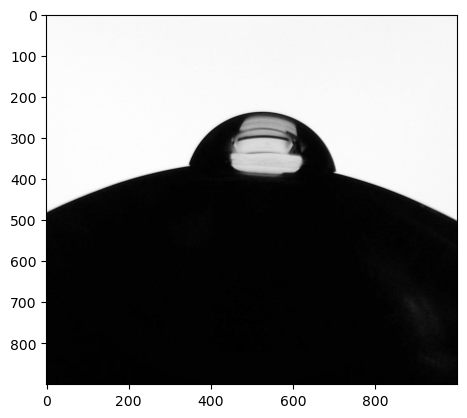

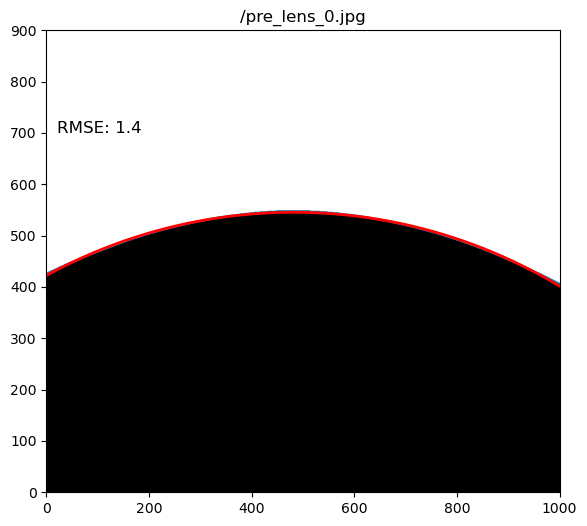

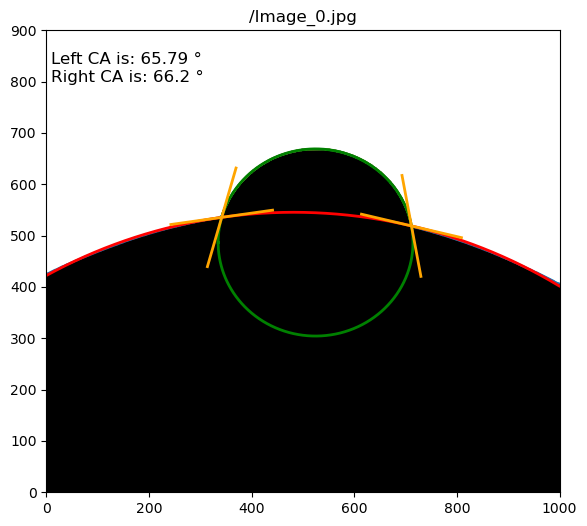

filename: 0_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/0_#0.png
3
/pre_lens_1.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.29723329 -456.76157727 1000.         1002.58099785]
4
/Image_1.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:324: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:132: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:132: RuntimeWarning: invalid value encountered in multiply
  return (m * x) + b


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [525.0566647  555.32589833 157.44333047 136.65945314]
NRSME: 0.018538366127721712

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  568.0 vs tangent line y :  574.6666666666667
droplet contour x:  366.5 vs tangent line x :  [366.5] 

RIGHT SIDE:
droplet contour y:  559.0 vs tangent line y:  nan
droplet contour x:  684.5 vs tangent line x :  [683.5] 

left_cut = 0
right_cut = 2


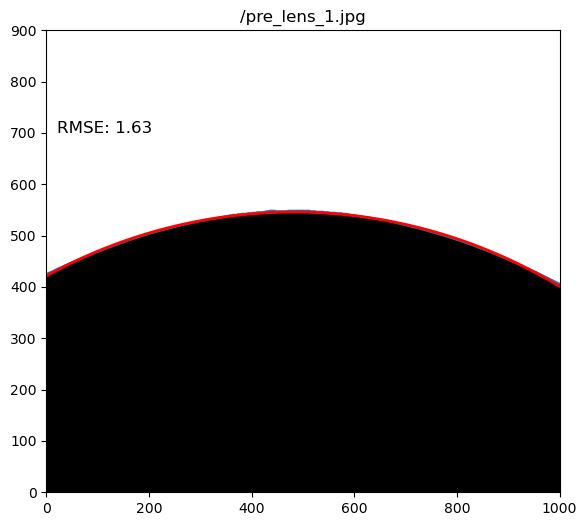

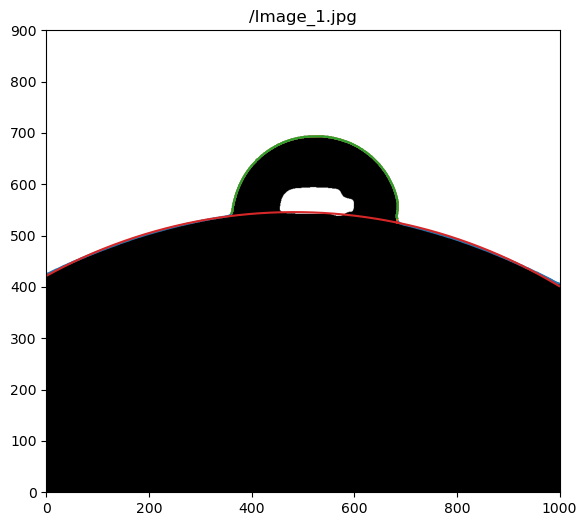

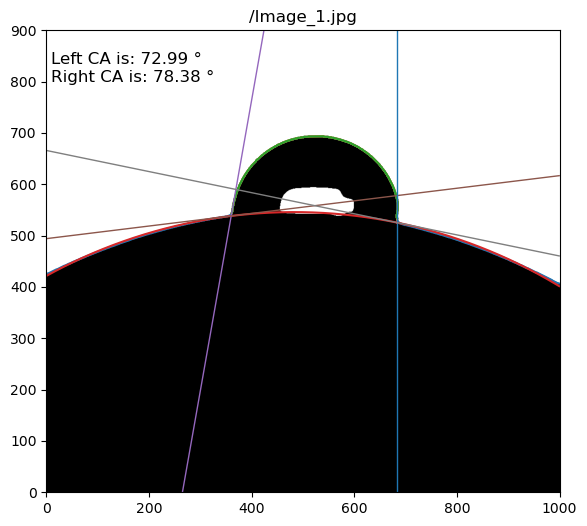

filename: 1_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/1_#0.png
5
/pre_lens_2.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.48833984 -461.5529708  1000.         1007.50694192]
6
/Image_2.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [548.74800083 535.41013962 159.40303212 157.27068082]
NRSME: 0.0021217482633100705


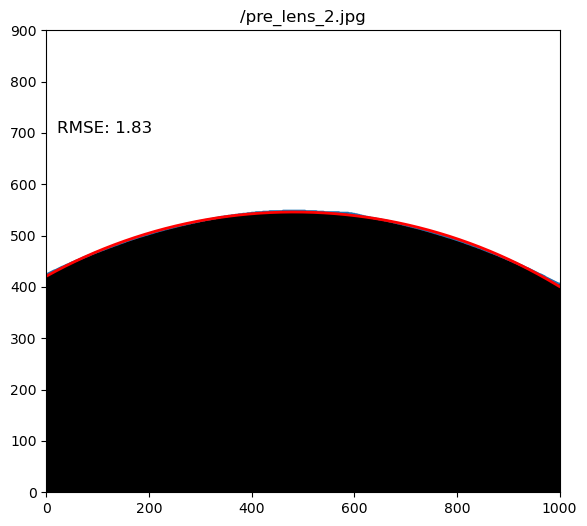

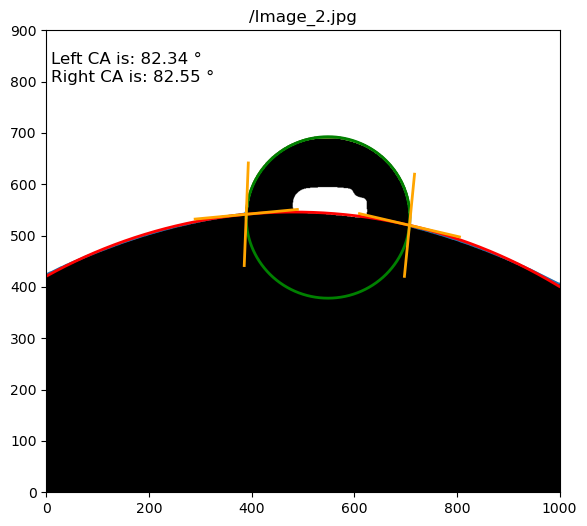

filename: 2_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/2_#0.png
7
/pre_lens_3.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.39804808 -464.3837339  1000.         1010.42572488]
8
/Image_3.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [517.38234414 546.91216999 158.11765253 150.19645627]
NRSME: 0.002281198529769565


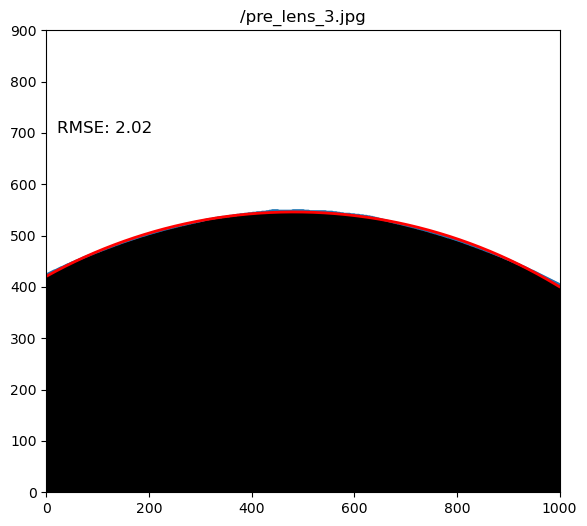

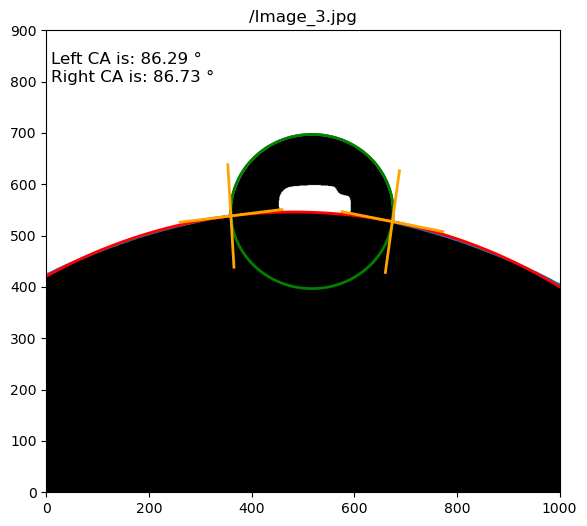

filename: 3_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/3_#0.png
9
/pre_lens_4.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.53648127 -467.97912222 1000.         1013.97908699]
10
/Image_4.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [517.71064175 545.39887806 156.79070019 149.13373765]
NRSME: 0.001985461341671299


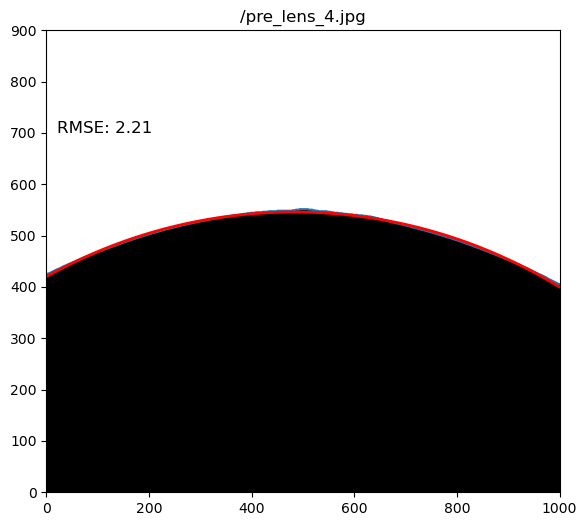

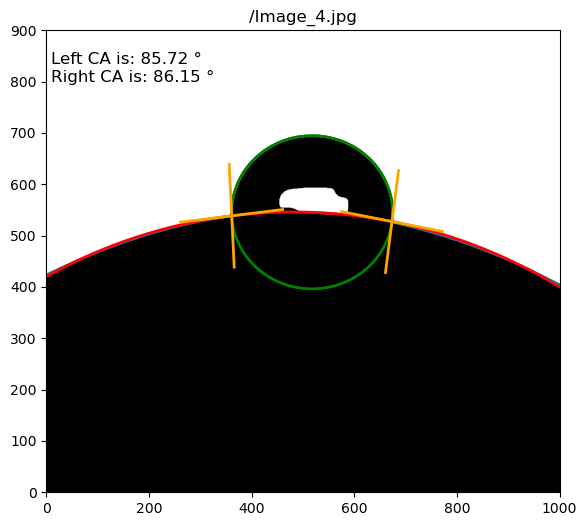

filename: 4_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/4_#0.png
11
/pre_lens_5.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.73301978 -476.1209069  1000.         1022.59365327]
12
/Image_5.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [495.56000242 539.43273491 161.41198164 154.59714732]
NRSME: 0.0027995048434823703


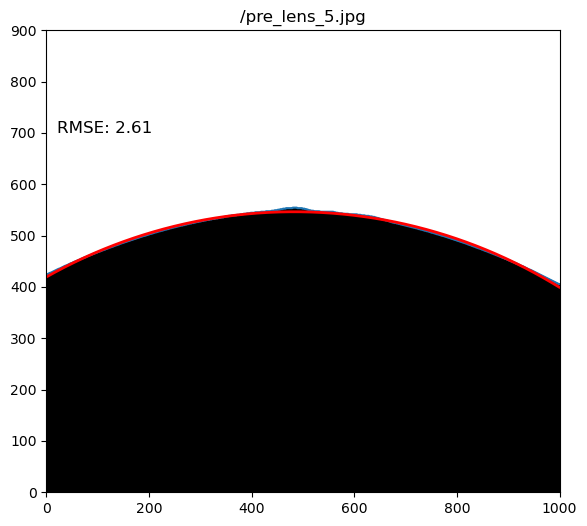

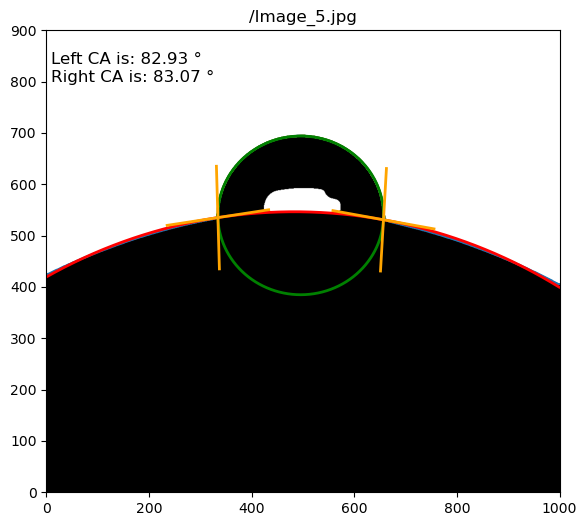

filename: 5_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/5_#0.png
13
/pre_lens_6.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.74748448 -482.70481916 1000.         1029.42622354]
14
/Image_6.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [523.3717271  519.58020691 176.00289614 164.425811  ]
NRSME: 0.002990970611048609


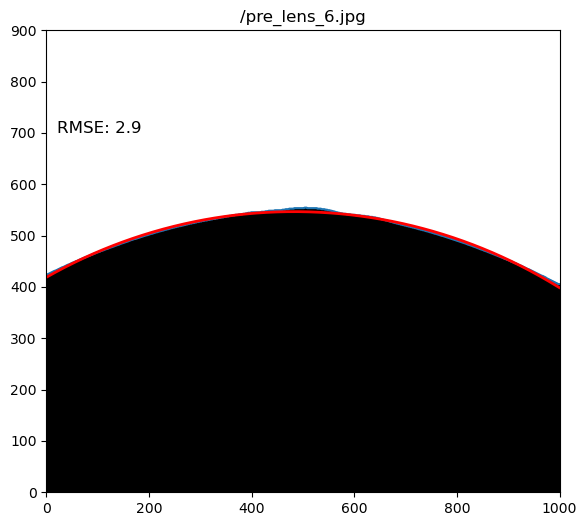

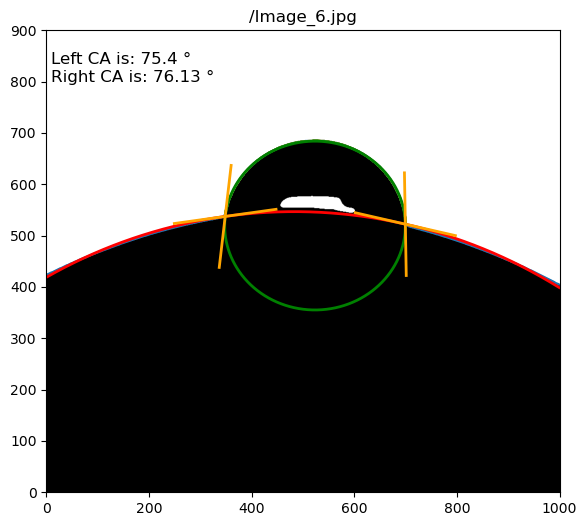

filename: 6_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/6_#0.png
15
/pre_lens_7.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.70093076 -479.16841469 1000.         1025.44914285]
16
/Image_7.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [544.34643419 529.87419999 165.96179059 162.12110892]
NRSME: 0.0019388568851940145


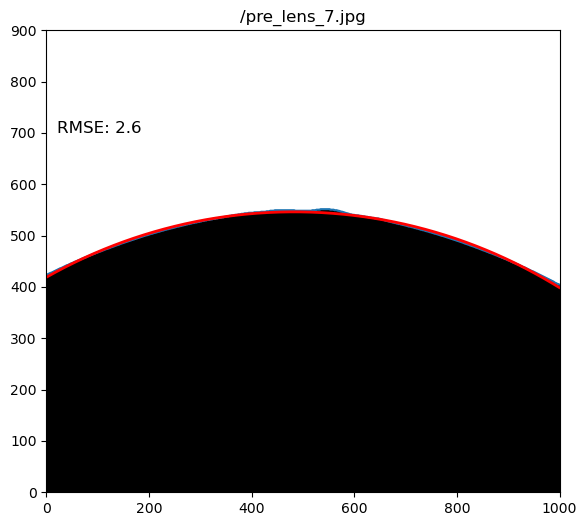

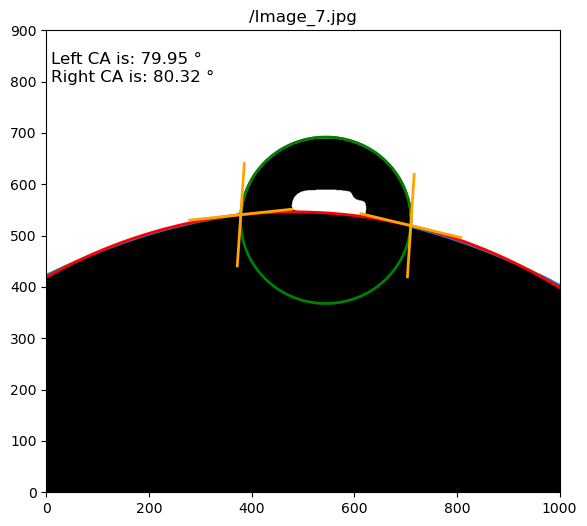

filename: 7_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/7_#0.png
17
/pre_lens_8.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 482.17967699 -479.56931343 1000.         1025.69787242]
18
/Image_8.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:308: RuntimeWarning: divide by zero encountered in scalar divide
  left_drop_slope = left_drop_vector[1]/left_drop_vector[0]
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:132: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:132: RuntimeWarning: invalid value encountered in multiply
  return (m * x) + b


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [485.09892076 559.51123864 152.40107238 138.17045262]
NRSME: 0.014589531268258316

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  568.0 vs tangent line y :  nan
droplet contour x:  331.5 vs tangent line x :  [331.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  568.0 vs tangent line y:  548.0
droplet contour x:  638.5 vs tangent line x :  [638.5] 

left_cut = 0
right_cut = 0


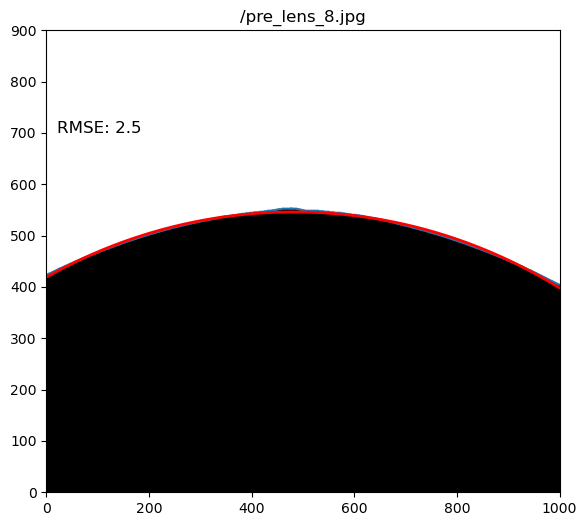

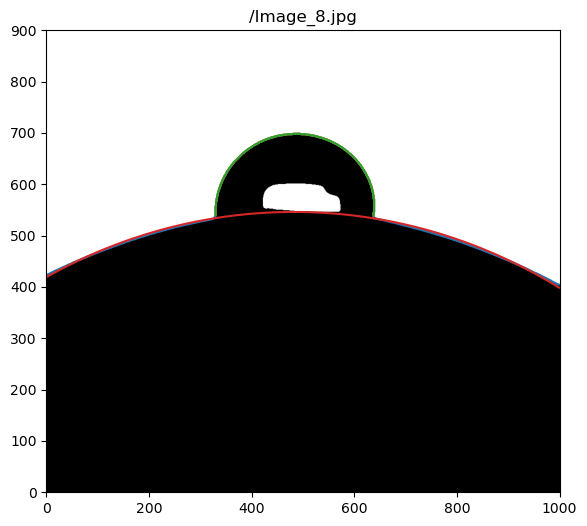

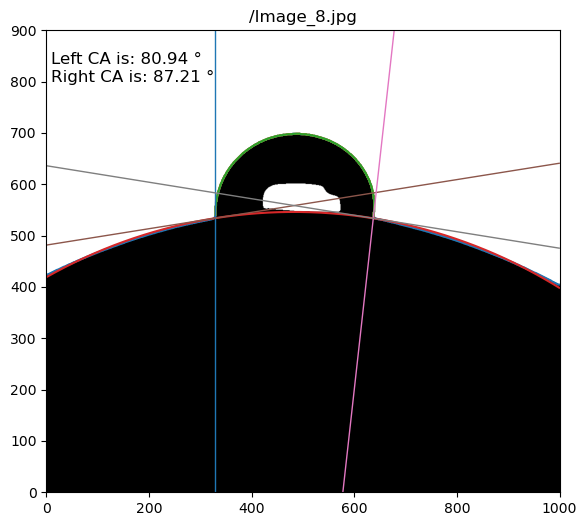

filename: 8_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/8_#0.png
19
/pre_lens_9.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 481.77302235 -477.67284655 1000.         1023.4434743 ]
20
/Image_9.jpg


C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:183: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
C:\Users\erin-\AppData\Local\Temp\ipykernel_51340\3099174110.py:184: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [514.86451574 557.92584987 148.97041846 141.00597968]
NRSME: 0.008409126889385799

RUNNING TANGENT METHOD:
LEFT SIDE:
droplet contour y:  573.0 vs tangent line y :  573.0
droplet contour x:  366.5 vs tangent line x :  [366.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  562.0 vs tangent line y:  552.0
droplet contour x:  665.5 vs tangent line x :  [665.5] 

left_cut = 1
right_cut = 0


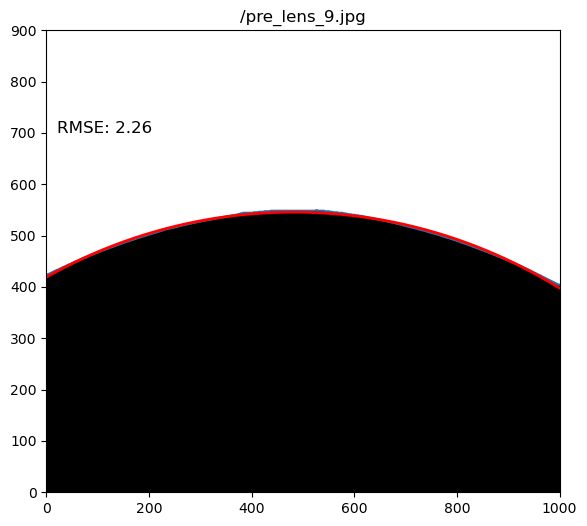

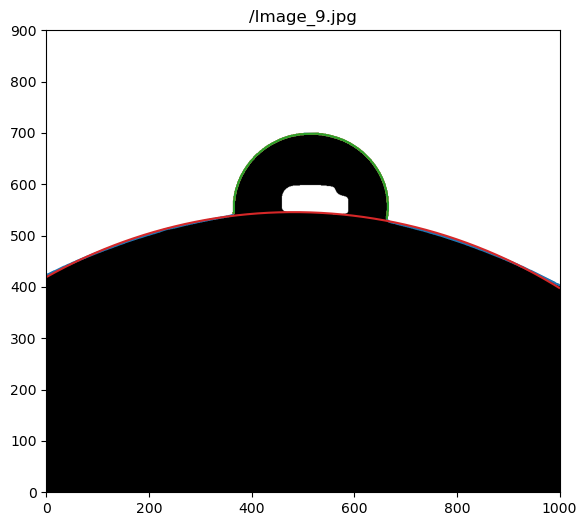

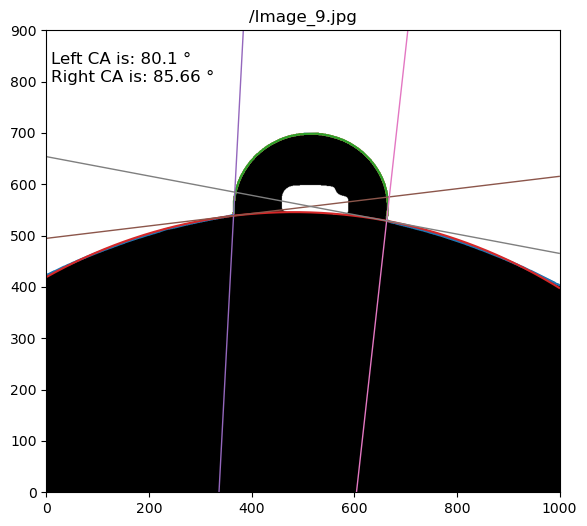

filename: 9_#0.png
full_path: ./Runs/20260413/20260413-senofilcon AOM-4p4m-RV-RT (3)/Processed_Data/9_#0.png


In [74]:
main(directory, curve_eqns_filepath, data_sum_filepath)